# 14. Optimización de hiperparámetros: resultados de la validación anidada

Este capítulo reporta lo que pasó al ejecutar el diseño del capítulo 13: las **140 combinaciones** del
enunciado (28 de regresión y 112 de clasificación). Las 28 de clasificación que las reglas del cap. 13
habían excluido también se ejecutaron completas, para cumplir el enunciado y para **verificar** si esas
reglas acertaban (14.7).
Responde a la sección 3 del enunciado:

1. cómo están configurados los cuatro optimizadores y por qué (sustituto, adquisición, operadores genéticos);
2. la **tabla maestra** con la métrica del **bucle externo** (media ± desviación), tiempos y presupuesto;
3. las **curvas anytime** (mejor valor hallado hasta la evaluación *t*);
4. la evidencia **cuantitativa** de eficiencia por unidad de presupuesto;
5. la diversidad genética del AG y la estabilidad de cada optimizador ante la semilla.

Todas las métricas que se reportan como desempeño vienen del **bucle externo**; los valores del bucle
interno solo se usan para estudiar la búsqueda (curvas anytime), nunca como estimación de generalización.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Tabla maestra y resultados de las 140 combinaciones
import json
from scipy.stats import wilcoxon
from src import benchmark as bm, resultados_e2 as r2
M = r2.maestro()
REG, CLF = r2.cargar("reg"), r2.cargar("clf")
OPT = bm.OPTIMIZADORES
COL = dict(zip(OPT, ["#7f7f7f", "#1f77b4", "#d62728", "#2ca02c"]))
print(f"Combinaciones completadas: regresión {len(REG)}, clasificación {len(CLF)}")

Combinaciones completadas: regresión 28, clasificación 112


## 14.1 Configuración de los cuatro optimizadores

Los cuatro métodos comparten **todo** salvo la estrategia de búsqueda: el mismo espacio (cap. 13.3), el
mismo presupuesto de **15 evaluaciones** y la misma función objetivo. Cada evaluación es una validación
temporal interna de 3 pliegues en la que el **Pipeline completo** (imputación, escalado, balanceo y modelo)
se ajusta solo con la parte de ajuste del pliegue: no hay fuga ni en Grid/Random ni en Optuna/DEAP, porque
la función objetivo construye el Pipeline dentro de cada pliegue (`src/benchmark.py`, `correr_combinacion`).

| Método | Implementación | Decisiones y justificación |
|---|---|---|
| **Grid Search** | rejilla propia de ≤ 15 puntos (`rejilla`) | Niveles en escala log para C, λ, learning rate y `min_samples_leaf`. Con 4–6 hiperparámetros solo caben 2 niveles en los primeros y el resto queda fijo en el centro: es la limitación conocida de Grid en alta dimensión. Por eso a veces usa **menos de 15 evaluaciones** (no hay más puntos). |
| **Random Search** | 15 muestras uniformes en el cubo [0,1]^d mapeadas al espacio (log cuando corresponde) | Línea base de Bergstra y Bengio (2012): cubre mejor las dimensiones importantes que Grid con el mismo presupuesto. |
| **Bayesiano** | Optuna 4.1, `TPESampler(multivariate=True, n_startup_trials=3)` | **Sustituto:** *Tree-structured Parzen Estimator*. En vez de modelar p(y∣x) como un proceso gaussiano, modela dos densidades: l(x) para las configuraciones buenas (cuantil superior γ) y g(x) para las demás. **Adquisición:** elige el candidato que maximiza l(x)/g(x), que es proporcional a la **Mejora Esperada (EI)** (Bergstra et al., 2011). Las 3 primeras evaluaciones son aleatorias (exploración); después EI concentra la búsqueda cerca de lo bueno (explotación). `multivariate=True` modela dependencias entre hiperparámetros (p. ej. learning rate × número de árboles). |
| **Genético** | DEAP 1.4 con genes en [0,1]^d | **Selección:** torneo de tamaño 3 (presión moderada, no depende de la escala de la aptitud). **Cruce:** BLX-α (`cxBlend`, α = 0,5) con probabilidad 0,7. **Mutación:** gaussiana σ = 0,15 por gen con prob. 0,5, aplicada al individuo con prob. 0,3. **Elitismo:** el mejor pasa intacto. **Población:** 4 individuos → 1 generación inicial + ~4 generaciones con 15 evaluaciones. Se registra la **diversidad** (distancia media entre individuos) en cada generación. Si la población converge a individuos ya evaluados, se reinyectan individuos aleatorios para no gastar presupuesto. |

Con solo 15 evaluaciones, la población del AG es necesariamente pequeña: el presupuesto igual para los
cuatro métodos es la condición para que la comparación sea justa (cap. 13.2), y el AG paga ese precio.

## 14.2 Tabla maestra de resultados (bucle externo)

In [3]:
# Resultados por combinación: métrica externa, evaluaciones y tiempos
filas = []
for r in REG + CLF:
    t_eval = np.concatenate([h["tiempos"] for h in r["historial"]] + [r["historial_final"]["tiempos"]])
    filas.append({"tarea": r["tarea"], "modelo": r["modelo"], "balanceo": r["balanceo"], "optimizador": r["optimizador"],
                  "métrica": r["metrica_principal"], "externo_media": r["externo_media"], "externo_desv": r["externo_desv"],
                  "evaluaciones": r["evaluaciones"], "t_total_min": r["t_total_s"] / 60, "t_por_eval_s": float(np.median(t_eval)),
                  "hiperparámetros finales": r2.params(r)})
T = pd.DataFrame(filas)
eda.guardar_tabla(T, "e2_tabla_maestra.csv")
T[T.tarea == "reg"].drop(columns=["tarea", "balanceo"]).sort_values("externo_media").round(4)

,modelo,optimizador,métrica,externo_media,externo_desv,evaluaciones,t_total_min,t_por_eval_s,hiperparámetros finales
21,XGBoost,Random,RMSLE,0.3175,0.0264,60,2.0984,1.8781,"{""n_estimators"": 421, ""max_depth"": 4, ""learnin..."
23,XGBoost,Genético (DEAP),RMSLE,0.3177,0.0258,60,2.0149,1.8970,"{""n_estimators"": 421, ""max_depth"": 4, ""learnin..."
22,XGBoost,Bayesiano (TPE),RMSLE,0.3182,0.0266,60,1.9739,1.8890,"{""n_estimators"": 403, ""max_depth"": 4, ""learnin..."
17,Random Forest,Random,RMSLE,0.3185,0.0249,60,55.8883,7.1495,"{""n_estimators"": 248, ""max_depth"": 7, ""min_sam..."
20,XGBoost,Grid,RMSLE,0.3191,0.0264,32,1.6524,2.0799,"{""n_estimators"": 100, ""max_depth"": 2, ""learnin..."
19,Random Forest,Genético (DEAP),RMSLE,0.3192,0.0256,60,55.3604,6.9915,"{""n_estimators"": 157, ""max_depth"": 14, ""min_sa..."
18,Random Forest,Bayesiano (TPE),RMSLE,0.3197,0.0269,60,56.7060,7.0179,"{""n_estimators"": 220, ""max_depth"": 8, ""min_sam..."
1,KNN,Random,RMSLE,0.3234,0.0251,60,1.1510,1.0518,"{""n_neighbors"": 75, ""weights"": ""uniform""}"
16,Random Forest,Grid,RMSLE,0.3236,0.0257,32,4.4419,5.9695,"{""n_estimators"": 50, ""max_depth"": 4, ""min_samp..."
3,KNN,Genético (DEAP),RMSLE,0.3238,0.0244,60,1.1598,1.0823,"{""n_neighbors"": 75, ""weights"": ""uniform""}"


**Regresión (RMSLE externo, menor es mejor).** La tabla está ordenada de mejor a peor.

In [4]:
# Lectura de los resultados de regresión
tr_ = T[T.tarea == "reg"].sort_values("externo_media")
md(f"- El mejor es **{tr_.modelo.iloc[0]} con {tr_.optimizador.iloc[0]}** (RMSLE externo {tr_.externo_media.iloc[0]:.4f} ± "
   f"{tr_.externo_desv.iloc[0]:.4f}), y las cuatro versiones de XGBoost quedan entre las "
   f"{int(tr_.reset_index().index[tr_.modelo.values == 'XGBoost'].max()) + 1} primeras.\n"
   f"- La desviación entre los 3 bloques externos (≈ {tr_.externo_desv.median():.3f}) es **mucho mayor** que la diferencia "
   f"entre optimizadores de un mismo modelo (p. ej. XGBoost: {tr_[tr_.modelo == 'XGBoost'].externo_media.min():.4f} a "
   f"{tr_[tr_.modelo == 'XGBoost'].externo_media.max():.4f}). La variación de un año a otro pesa más que el optimizador; "
   f"el cap. 20 lo cuantifica y el cap. 21 lo prueba formalmente.\n"
   f"- Ridge y Lasso dan el mismo RMSLE con los cuatro optimizadores: la superficie del objetivo es casi plana en λ "
   f"(18 predictoras, ~31 000 filas), así que cualquier método encuentra el óptimo.")

- El mejor es **XGBoost con Random** (RMSLE externo 0.3175 ± 0.0264), y las cuatro versiones de XGBoost quedan entre las 5 primeras.
- La desviación entre los 3 bloques externos (≈ 0.026) es **mucho mayor** que la diferencia entre optimizadores de un mismo modelo (p. ej. XGBoost: 0.3175 a 0.3191). La variación de un año a otro pesa más que el optimizador; el cap. 20 lo cuantifica y el cap. 21 lo prueba formalmente.
- Ridge y Lasso dan el mismo RMSLE con los cuatro optimizadores: la superficie del objetivo es casi plana en λ (18 predictoras, ~31 000 filas), así que cualquier método encuentra el óptimo.

In [5]:
T[T.tarea == "clf"].drop(columns=["tarea"]).sort_values("externo_media", ascending=False).head(25).round(4)

,modelo,balanceo,optimizador,métrica,externo_media,externo_desv,evaluaciones,t_total_min,t_por_eval_s,hiperparámetros finales
89,XGBoost,sin balanceo,Random,ROC_AUC,0.7781,0.0334,60,34.5558,2.1295,"{""n_estimators"": 222, ""max_depth"": 3, ""learnin..."
91,XGBoost,sin balanceo,Genético (DEAP),ROC_AUC,0.7779,0.0347,60,34.3814,2.0446,"{""n_estimators"": 428, ""max_depth"": 3, ""learnin..."
90,XGBoost,sin balanceo,Bayesiano (TPE),ROC_AUC,0.7778,0.0334,60,34.5019,2.1037,"{""n_estimators"": 331, ""max_depth"": 3, ""learnin..."
86,XGBoost,class_weight,Bayesiano (TPE),ROC_AUC,0.7772,0.0327,60,34.5433,2.1076,"{""n_estimators"": 417, ""max_depth"": 3, ""learnin..."
85,XGBoost,class_weight,Random,ROC_AUC,0.7766,0.0342,60,34.6984,2.1275,"{""n_estimators"": 222, ""max_depth"": 3, ""learnin..."
87,XGBoost,class_weight,Genético (DEAP),ROC_AUC,0.7765,0.0349,60,2.1816,1.8704,"{""n_estimators"": 222, ""max_depth"": 3, ""learnin..."
69,Random Forest,class_weight,Random,ROC_AUC,0.7755,0.0355,60,11.2389,7.0355,"{""n_estimators"": 248, ""max_depth"": 7, ""min_sam..."
75,Random Forest,sin balanceo,Genético (DEAP),ROC_AUC,0.7749,0.0373,60,20.6399,6.5776,"{""n_estimators"": 101, ""max_depth"": 6, ""min_sam..."
65,Random Forest,SMOTE,Random,ROC_AUC,0.7744,0.0317,60,32.4064,24.4297,"{""n_estimators"": 101, ""max_depth"": 6, ""min_sam..."
88,XGBoost,sin balanceo,Grid,ROC_AUC,0.7744,0.0324,32,1.2653,1.7462,"{""n_estimators"": 600, ""max_depth"": 2, ""learnin..."


In [6]:
# Lectura de los resultados de clasificación
tc_ = T[T.tarea == "clf"].sort_values("externo_media", ascending=False)
md(f"**Clasificación (ROC-AUC externo, mayor es mejor; se muestran las 25 primeras de {len(tc_)}).** La mejor es "
   f"**{tc_.modelo.iloc[0]} · {tc_.balanceo.iloc[0]} · {tc_.optimizador.iloc[0]}** (AUC {tc_.externo_media.iloc[0]:.4f} ± "
   f"{tc_.externo_desv.iloc[0]:.4f}). Las {len(tc_)} combinaciones caen entre {tc_.externo_media.min():.3f} y {tc_.externo_media.max():.3f}: "
   f"el rango completo equivale a ~{(tc_.externo_media.max() - tc_.externo_media.min()) / tc_.externo_desv.median():.1f} desviaciones "
   f"típicas entre bloques externos.")

**Clasificación (ROC-AUC externo, mayor es mejor; se muestran las 25 primeras de 112).** La mejor es **XGBoost · sin balanceo · Random** (AUC 0.7781 ± 0.0334). Las 112 combinaciones caen entre 0.678 y 0.778: el rango completo equivale a ~2.9 desviaciones típicas entre bloques externos.

### Campeones: la mejor combinación de cada modelo

Para cada uno de los 7 modelos se elige **una sola** combinación, la de mejor métrica en el **bucle externo**
(RMSLE en regresión, ROC-AUC en clasificación), con datos de entrenamiento únicamente. Resume qué
configuración de cada familia rinde mejor en la validación anidada. En la evaluación final en origen móvil
(cap. 13.11) cada familia tiene su propio campeón, elegido con la validación anterior a 2016, que es el que se
compara con el modelo propuesto (cap. 22.4) y entra a Friedman, Nemenyi y las pruebas de independencia
(cap. 21). Comparar contra un representante por familia, y no contra las 28 o 112 combinaciones, evita corregir
por muchas comparaciones casi redundantes entre versiones de un mismo modelo.

In [7]:
# Campeón de cada familia (mejor combinación del modelo)
def campeones(tarea):
    sub = T[T.tarea == tarea]
    idx = sub.groupby("modelo").externo_media.idxmin() if tarea == "reg" else sub.groupby("modelo").externo_media.idxmax()
    c = sub.loc[idx].sort_values("externo_media", ascending=(tarea == "reg")).copy()
    c.insert(0, "puesto", range(1, len(c) + 1))
    c["combinación"] = c.optimizador if tarea == "reg" else c.balanceo + " · " + c.optimizador
    c["métrica externa"] = c.externo_media.map(lambda v: f"{v:.4f}") + " ± " + c.externo_desv.map(lambda v: f"{v:.4f}")
    return c[["puesto", "modelo", "combinación", "métrica externa", "t_total_min", "hiperparámetros finales"]]

CAMP_R, CAMP_C = campeones("reg"), campeones("clf")
eda.guardar_tabla(CAMP_R, "e2_campeones_regresion.csv"); eda.guardar_tabla(CAMP_C, "e2_campeones_clasificacion.csv")
md("**Regresión: campeón de cada modelo (RMSLE externo, menor es mejor)**")
CAMP_R.round(2)

**Regresión: campeón de cada modelo (RMSLE externo, menor es mejor)**

,puesto,modelo,combinación,métrica externa,t_total_min,hiperparámetros finales
21,1,XGBoost,Random,0.3175 ± 0.0264,2.10,"{""n_estimators"": 421, ""max_depth"": 4, ""learnin..."
17,2,Random Forest,Random,0.3185 ± 0.0249,55.89,"{""n_estimators"": 248, ""max_depth"": 7, ""min_sam..."
1,3,KNN,Random,0.3234 ± 0.0251,1.15,"{""n_neighbors"": 75, ""weights"": ""uniform""}"
12,4,Árbol de decisión,Grid,0.3263 ± 0.0266,0.20,"{""max_depth"": 8, ""min_samples_leaf"": 5}"
26,5,SVR,Bayesiano (TPE),0.3327 ± 0.0257,2.98,"{""C"": 0.2919, ""epsilon"": 0.1635, ""gamma"": 0.0029}"
7,6,Ridge,Genético (DEAP),0.3341 ± 0.0251,0.09,"{""alpha"": 0.001}"
11,7,Lasso,Genético (DEAP),0.3341 ± 0.0251,0.14,"{""alpha"": 0.0}"


In [8]:
md("**Clasificación: campeón de cada modelo (ROC-AUC externo, mayor es mejor)**")
CAMP_C.round(2)

**Clasificación: campeón de cada modelo (ROC-AUC externo, mayor es mejor)**

,puesto,modelo,combinación,métrica externa,t_total_min,hiperparámetros finales
89,1,XGBoost,sin balanceo · Random,0.7781 ± 0.0334,34.56,"{""n_estimators"": 222, ""max_depth"": 3, ""learnin..."
69,2,Random Forest,class_weight · Random,0.7755 ± 0.0355,11.24,"{""n_estimators"": 248, ""max_depth"": 7, ""min_sam..."
37,3,KNN,class_weight · Random,0.7727 ± 0.0296,1.65,"{""n_neighbors"": 189, ""weights"": ""uniform""}"
121,4,Regresión logística (L1/L2),sin balanceo · Random,0.7700 ± 0.0364,0.29,"{""C"": 0.0116, ""penalty"": ""l1""}"
125,5,SVM,ADASYN · Random,0.7665 ± 0.0366,5.23,"{""C"": 0.2167, ""gamma"": 0.0076}"
92,6,Naive Bayes,ADASYN · Grid,0.7643 ± 0.0319,1.19,"{""var_smoothing"": 0.1}"
52,7,Árbol de decisión,class_weight · Grid,0.7637 ± 0.0378,0.22,"{""max_depth"": 14, ""min_samples_leaf"": 500}"


In [9]:
md(f"- **Regresión.** El orden de familias es {', '.join(CAMP_R.modelo)}. XGBoost y Random Forest quedan muy cerca "
   f"({CAMP_R['métrica externa'].iloc[0].split(' ±')[0]} frente a {CAMP_R['métrica externa'].iloc[1].split(' ±')[0]}); los modelos lineales "
   f"(Ridge, Lasso) y SVR son claramente peores.\n"
   f"- **Clasificación.** El orden es {', '.join(CAMP_C.modelo)}. Ganan {CAMP_C.modelo.iloc[0]} ({CAMP_C.combinación.iloc[0]}) y "
   f"{CAMP_C.modelo.iloc[1]} ({CAMP_C.combinación.iloc[1]}).\n"
   f"- En KNN gana por 0,00002 de AUC la versión con class_weight, que el cap. 13.6 demostró equivalente a «sin balanceo» (ordena las "
   f"celdas igual): da lo mismo cuál de las dos represente a KNN.\n"
   f"- El optimizador que produjo cada campeón varía de un modelo a otro: ninguno gana siempre, coherente con lo que muestran las "
   f"secciones siguientes.")

- **Regresión.** El orden de familias es XGBoost, Random Forest, KNN, Árbol de decisión, SVR, Ridge, Lasso. XGBoost y Random Forest quedan muy cerca (0.3175 frente a 0.3185); los modelos lineales (Ridge, Lasso) y SVR son claramente peores.
- **Clasificación.** El orden es XGBoost, Random Forest, KNN, Regresión logística (L1/L2), SVM, Naive Bayes, Árbol de decisión. Ganan XGBoost (sin balanceo · Random) y Random Forest (class_weight · Random).
- En KNN gana por 0,00002 de AUC la versión con class_weight, que el cap. 13.6 demostró equivalente a «sin balanceo» (ordena las celdas igual): da lo mismo cuál de las dos represente a KNN.
- El optimizador que produjo cada campeón varía de un modelo a otro: ninguno gana siempre, coherente con lo que muestran las secciones siguientes.

### Comparación de los optimizadores por métrica, tiempo y presupuesto

Para comparar optimizadores sin mezclar modelos, cada **grupo** (modelo × balanceo) se trata como un bloque:
dentro de él se ordenan los 4 optimizadores por la métrica externa (1 = mejor) y se promedian los rangos.

In [10]:
# Ranking de optimizadores dentro de cada modelo y prueba de Friedman
def rangos_opt(df, menor_mejor):
    g = df.pivot_table(index=["modelo", "balanceo"], columns="optimizador", values="externo_media")[OPT]
    R = g.rank(axis=1, ascending=menor_mejor)
    return g, R

resumen = []
for tarea, menor in (("reg", True), ("clf", False)):
    d = T[T.tarea == tarea]
    g, R = rangos_opt(d, menor)
    fr = stats.friedmanchisquare(*[g[o].values for o in OPT])
    for o in OPT:
        s = d[d.optimizador == o]
        resumen.append({"tarea": tarea, "optimizador": o, "rango_medio": R[o].mean(), "veces_mejor": int((R[o] == 1).sum()),
                        "grupos": len(R), "métrica_externa_media": s.externo_media.mean(), "evaluaciones_medias": s.evaluaciones.mean(),
                        "t_total_medio_min": s.t_total_min.mean(), "t_por_eval_mediana_s": s.t_por_eval_s.median(),
                        "Friedman_p (entre optimizadores)": fr.pvalue})
RO = pd.DataFrame(resumen)
eda.guardar_tabla(RO, "e2_optimizadores_resumen.csv")
RO.round(4)

,tarea,optimizador,rango_medio,veces_mejor,grupos,métrica_externa_media,evaluaciones_medias,t_total_medio_min,t_por_eval_mediana_s,Friedman_p (entre optimizadores)
0,reg,Grid,3.1429,1,7,0.3300,48.0000,8.2741,1.0419,0.4188
1,reg,Random,2.1429,3,7,0.3283,60.0000,15.8512,1.0518,0.4188
2,reg,Bayesiano (TPE),2.5714,1,7,0.3277,60.0000,9.0506,1.1209,0.4188
3,reg,Genético (DEAP),2.1429,2,7,0.3320,60.0000,8.8069,1.0823,0.4188
4,clf,Grid,2.3571,10,28,0.7623,47.4286,7.3265,1.7456,0.7086
5,clf,Random,2.4107,11,28,0.7613,60.0000,11.2301,1.8617,0.7086
6,clf,Bayesiano (TPE),2.5000,4,28,0.7634,60.0000,12.1109,1.9829,0.7086
7,clf,Genético (DEAP),2.7321,3,28,0.7607,60.0000,10.1500,1.7896,0.7086


In [11]:
# Lectura de la comparación de optimizadores
p_reg = RO[RO.tarea == "reg"]["Friedman_p (entre optimizadores)"].iloc[0]
p_clf = RO[RO.tarea == "clf"]["Friedman_p (entre optimizadores)"].iloc[0]
mej = {t: RO[RO.tarea == t].sort_values("rango_medio").optimizador.iloc[0] for t in ("reg", "clf")}
peor = {t: RO[RO.tarea == t].sort_values("rango_medio").optimizador.iloc[-1] for t in ("reg", "clf")}
md(f"- **Por métrica externa.** El mejor rango medio lo tiene **{mej['reg']}** en regresión y **{mej['clf']}** en "
   f"clasificación; el peor, {peor['reg']} y {peor['clf']}. La prueba de Friedman entre optimizadores (bloques = grupos) da "
   f"p = {p_fmt(p_reg)} en regresión y p = {p_fmt(p_clf)} en clasificación"
   + (": en regresión **no** hay evidencia de que el optimizador cambie la métrica externa" if p_reg >= 0.05 else "")
   + (", y en clasificación sí hay diferencias" if p_clf < 0.05 else ", y en clasificación tampoco") + ".\n"
   f"- **Por presupuesto.** Grid usa en promedio menos de 15 evaluaciones porque su rejilla tiene menos puntos; "
   f"los otros tres agotan las 15.\n"
   f"- **Por tiempo.** El tiempo por evaluación lo domina el ajuste del modelo, no el optimizador: la mediana es "
   f"parecida en los cuatro. El sobrecosto de TPE (ajustar el sustituto) y del AG (operadores) es de milisegundos frente "
   f"a segundos de cada validación interna. Los tiempos totales se midieron con varias combinaciones corriendo en paralelo en "
   f"la máquina de los autores, así que tienen ruido de contención; por eso se comparan medianas.")

- **Por métrica externa.** El mejor rango medio lo tiene **Random** en regresión y **Grid** en clasificación; el peor, Grid y Genético (DEAP). La prueba de Friedman entre optimizadores (bloques = grupos) da p = 0,419 en regresión y p = 0,709 en clasificación: en regresión **no** hay evidencia de que el optimizador cambie la métrica externa, y en clasificación tampoco.
- **Por presupuesto.** Grid usa en promedio menos de 15 evaluaciones porque su rejilla tiene menos puntos; los otros tres agotan las 15.
- **Por tiempo.** El tiempo por evaluación lo domina el ajuste del modelo, no el optimizador: la mediana es parecida en los cuatro. El sobrecosto de TPE (ajustar el sustituto) y del AG (operadores) es de milisegundos frente a segundos de cada validación interna. Los tiempos totales se midieron con varias combinaciones corriendo en paralelo en la máquina de los autores, así que tienen ruido de contención; por eso se comparan medianas.

## 14.3 Curvas anytime: mejor valor hallado hasta la evaluación *t*

Para cada búsqueda (3 pliegues externos + la búsqueda final de cada combinación) se calcula el mejor valor
del objetivo interno hasta la evaluación *t*. Para promediar entre modelos de escalas distintas se usa el
**regret relativo**: la distancia (en %) entre ese valor y el mejor valor que **cualquiera** de los 4
optimizadores encontró para el mismo grupo y pliegue. Regret 0 = ya encontró el mejor conocido.
Cuando Grid agota su rejilla antes de 15, su curva se mantiene plana (no tiene más puntos que evaluar).

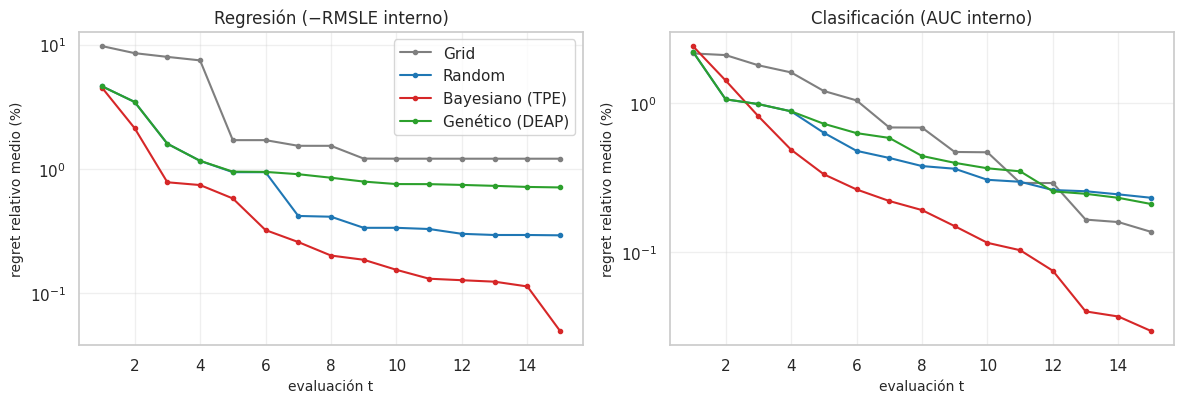

In [12]:
# Curvas anytime: mejor valor acumulado por evaluación (regret relativo)
filas = []
for r in REG + CLF:
    for h in r["historial"] + [dict(r["historial_final"], pliegue="final")]:
        v = np.maximum.accumulate(np.array(h["valores"]))
        v = np.concatenate([v, np.repeat(v[-1], 15 - len(v))])
        tc = np.cumsum(np.concatenate([h["tiempos"], np.zeros(15 - len(h["tiempos"]))]))
        for t, (x, s) in enumerate(zip(v, tc)):
            filas.append({"tarea": r["tarea"], "grupo": f"{r['modelo']}|{r['balanceo']}", "pliegue": str(h["pliegue"]),
                          "optimizador": r["optimizador"], "t": t + 1, "mejor": x, "t_acum_s": s})
A = pd.DataFrame(filas)
ref = A.groupby(["tarea", "grupo", "pliegue"]).mejor.transform("max")
A["regret_%"] = 100 * (ref - A.mejor) / ref.abs()
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (tarea, nom) in zip(axs, (("reg", "Regresión (−RMSLE interno)"), ("clf", "Clasificación (AUC interno)"))):
    for o in OPT:
        c = A[(A.tarea == tarea) & (A.optimizador == o)].groupby("t")["regret_%"]
        m, q = c.mean(), c.quantile(0.75)
        ax.plot(m.index, m.values, marker="o", ms=3, color=COL[o], label=o)
    ax.set_yscale("symlog", linthresh=0.1); ax.set_xlabel("evaluación t"); ax.set_ylabel("regret relativo medio (%)")
    ax.set_title(nom); ax.grid(alpha=0.3)
axs[0].legend()
plt.tight_layout(); eda.guardar_figura(fig, "e2_anytime.png"); plt.show()

## 14.4 Evidencia cuantitativa de eficiencia por unidad de presupuesto

Tres medidas por búsqueda, comparadas con pruebas pareadas (Wilcoxon de rangos con signo, bloques =
grupo × pliegue, Holm sobre las comparaciones):

- **Regret final** (t = 15): calidad alcanzada con todo el presupuesto.
- **Área bajo la curva de regret** (media de las 15 evaluaciones): calidad **en cualquier momento**; premia
  llegar pronto a buenas soluciones.
- **Evaluaciones hasta quedar a menos de 0,5 % del mejor conocido** (16 = no lo logró): presupuesto necesario.

In [13]:
# Métricas de eficiencia: regret final, área bajo la curva y evaluaciones hasta 0,5 %
def hasta(g, umbral=0.5):
    ok = g["regret_%"].values <= umbral
    return int(np.argmax(ok)) + 1 if ok.any() else 16

met = A.groupby(["tarea", "grupo", "pliegue", "optimizador"]).apply(
    lambda g: pd.Series({"regret_final": g["regret_%"].iloc[-1], "area_regret": g["regret_%"].mean(), "evals_hasta_0.5%": hasta(g)})).reset_index()
tab = met.groupby(["tarea", "optimizador"])[["regret_final", "area_regret", "evals_hasta_0.5%"]].agg(["mean", "median"]).round(3)
eda.guardar_tabla(tab.reset_index(), "e2_eficiencia_optimizadores.csv")
tab

regret_final        area_regret        evals_hasta_0.5%       
                              mean median        mean median             mean median
tarea optimizador                                                                   
clf   Bayesiano (TPE)        0.052  0.007       0.450  0.241            3.652    3.0
      Genético (DEAP)        0.209  0.036       0.635  0.362            6.036    4.0
      Grid                   0.136  0.020       0.880  0.344            5.054    1.0
      Random                 0.230  0.087       0.598  0.354            5.571    4.0
reg   Bayesiano (TPE)        0.072  0.000       0.693  0.187            4.071    2.0
      Genético (DEAP)        0.706  0.005       1.308  0.158            4.321    1.0
      Grid                   1.203  0.265       3.238  0.883            7.393    5.0
      Random                 0.290  0.018       1.045  0.164            4.679    1.0

In [14]:
# Comparación pareada de optimizadores (Wilcoxon) con corrección de Holm
pruebas = []
for tarea in ("reg", "clf"):
    w = met[met.tarea == tarea].pivot_table(index=["grupo", "pliegue"], columns="optimizador", values="area_regret")
    for a, b_ in (("Bayesiano (TPE)", "Random"), ("Bayesiano (TPE)", "Grid"), ("Genético (DEAP)", "Random"), ("Genético (DEAP)", "Grid"), ("Random", "Grid")):
        d = w[a] - w[b_]
        st = wilcoxon(w[a], w[b_], zero_method="zsplit")
        pruebas.append({"tarea": tarea, "comparación": f"{a} vs {b_}", "dif_media_area": d.mean(), "mediana_dif": d.median(),
                        "% bloques en que A es mejor": 100 * (d < 0).mean(), "p": st.pvalue})
P = pd.DataFrame(pruebas)
P["p_Holm"] = np.concatenate([eda.holm(P[P.tarea == t].p.values) for t in ("reg", "clf")])
eda.guardar_tabla(P, "e2_eficiencia_pruebas.csv")
P.round(4)

,tarea,comparación,dif_media_area,mediana_dif,% bloques en que A es mejor,p,p_Holm
0,reg,Bayesiano (TPE) vs Random,-0.3521,0.0014,50.0000,0.7621,0.9045
1,reg,Bayesiano (TPE) vs Grid,-2.5450,-0.4182,64.2857,0.0007,0.0036
2,reg,Genético (DEAP) vs Random,0.2630,-0.0000,53.5714,0.4522,0.9045
3,reg,Genético (DEAP) vs Grid,-1.9299,-0.4016,57.1429,0.0191,0.0573
4,reg,Random vs Grid,-2.1929,-0.4706,64.2857,0.0017,0.0068
5,clf,Bayesiano (TPE) vs Random,-0.1483,-0.1005,60.7143,0.0100,0.0501
6,clf,Bayesiano (TPE) vs Grid,-0.4301,-0.0932,58.0357,0.0410,0.1639
7,clf,Genético (DEAP) vs Random,0.0373,0.0000,41.9643,0.0796,0.2388
8,clf,Genético (DEAP) vs Grid,-0.2445,-0.0129,50.8929,0.7297,1.0000
9,clf,Random vs Grid,-0.2817,-0.0076,51.7857,0.5498,1.0000


In [15]:
# Lectura de cada comparación de optimizadores
lin = []
for _, f in P.iterrows():
    sig = f.p_Holm < 0.05
    lin.append(f"- {'reg.' if f.tarea == 'reg' else 'clf.'} **{f['comparación']}**: área de regret media {f.dif_media_area:+.3f} pp "
               f"(negativo = el primero es mejor), mejor en {f['% bloques en que A es mejor']:.0f} % de los bloques, p Holm = {p_fmt(f.p_Holm)}"
               f"{' → diferencia significativa' if sig else ' → sin diferencia significativa'}.")
md("\n".join(lin))

- reg. **Bayesiano (TPE) vs Random**: área de regret media -0.352 pp (negativo = el primero es mejor), mejor en 50 % de los bloques, p Holm = 0,904 → sin diferencia significativa.
- reg. **Bayesiano (TPE) vs Grid**: área de regret media -2.545 pp (negativo = el primero es mejor), mejor en 64 % de los bloques, p Holm = 0,004 → diferencia significativa.
- reg. **Genético (DEAP) vs Random**: área de regret media +0.263 pp (negativo = el primero es mejor), mejor en 54 % de los bloques, p Holm = 0,904 → sin diferencia significativa.
- reg. **Genético (DEAP) vs Grid**: área de regret media -1.930 pp (negativo = el primero es mejor), mejor en 57 % de los bloques, p Holm = 0,057 → sin diferencia significativa.
- reg. **Random vs Grid**: área de regret media -2.193 pp (negativo = el primero es mejor), mejor en 64 % de los bloques, p Holm = 0,007 → diferencia significativa.
- clf. **Bayesiano (TPE) vs Random**: área de regret media -0.148 pp (negativo = el primero es mejor), mejor en 61 % de los bloques, p Holm = 0,050 → sin diferencia significativa.
- clf. **Bayesiano (TPE) vs Grid**: área de regret media -0.430 pp (negativo = el primero es mejor), mejor en 58 % de los bloques, p Holm = 0,164 → sin diferencia significativa.
- clf. **Genético (DEAP) vs Random**: área de regret media +0.037 pp (negativo = el primero es mejor), mejor en 42 % de los bloques, p Holm = 0,239 → sin diferencia significativa.
- clf. **Genético (DEAP) vs Grid**: área de regret media -0.244 pp (negativo = el primero es mejor), mejor en 51 % de los bloques, p Holm = 1,000 → sin diferencia significativa.
- clf. **Random vs Grid**: área de regret media -0.282 pp (negativo = el primero es mejor), mejor en 52 % de los bloques, p Holm = 1,000 → sin diferencia significativa.

In [16]:
# Lectura global de la eficiencia
ar = tab["area_regret"]["mean"].unstack(0)
sig = P[P.p_Holm < 0.05]
md(f"**Lectura.**\n\n"
   f"- **Bayesiano (TPE) tiene el área de regret media más baja en las dos tareas** (regresión {ar.loc['Bayesiano (TPE)', 'reg']:.2f} pp, "
   f"clasificación {ar.loc['Bayesiano (TPE)', 'clf']:.2f} pp) y, en promedio, necesita menos evaluaciones para quedar a 0,5 % del mejor conocido: después "
   f"de las 3 evaluaciones de arranque, la Mejora Esperada concentra el muestreo donde l(x)/g(x) es alto.\n"
   f"- **Pero la ventaja solo es significativa frente a Grid.** Tras Holm, las diferencias significativas son: "
   + (", ".join(f"{f['comparación']} ({'reg.' if f.tarea == 'reg' else 'clf.'}, p = {p_fmt(f.p_Holm)})" for _, f in sig.iterrows()) or "ninguna")
   + ". TPE frente a Random y el AG frente a Random no se distinguen: con solo 15 evaluaciones, TPE pasa un 20 % del presupuesto en "
   "arranque aleatorio y el AG, con población 4, se parece mucho a Random (su generación inicial **es** aleatoria). De hecho, en "
   "XGBoost de regresión el AG y Random encontraron **la misma configuración**: con la misma semilla, la población inicial del AG "
   "coincide con las primeras muestras de Random y el élite nunca fue superado.\n"
   f"- **Grid es el menos eficiente** cuando el espacio tiene más de 2–3 hiperparámetros (XGBoost, Random Forest, SVR), porque fija en "
   f"el centro los que no caben en la rejilla.\n"
   f"- La ventaja de un método de búsqueda **interna** no se traslada al bucle **externo** (14.2): las mejoras de la búsqueda son "
   f"de décimas de punto porcentual, menores que la variación entre años.")

**Lectura.**

- **Bayesiano (TPE) tiene el área de regret media más baja en las dos tareas** (regresión 0.69 pp, clasificación 0.45 pp) y, en promedio, necesita menos evaluaciones para quedar a 0,5 % del mejor conocido: después de las 3 evaluaciones de arranque, la Mejora Esperada concentra el muestreo donde l(x)/g(x) es alto.
- **Pero la ventaja solo es significativa frente a Grid.** Tras Holm, las diferencias significativas son: Bayesiano (TPE) vs Grid (reg., p = 0,004), Random vs Grid (reg., p = 0,007). TPE frente a Random y el AG frente a Random no se distinguen: con solo 15 evaluaciones, TPE pasa un 20 % del presupuesto en arranque aleatorio y el AG, con población 4, se parece mucho a Random (su generación inicial **es** aleatoria). De hecho, en XGBoost de regresión el AG y Random encontraron **la misma configuración**: con la misma semilla, la población inicial del AG coincide con las primeras muestras de Random y el élite nunca fue superado.
- **Grid es el menos eficiente** cuando el espacio tiene más de 2–3 hiperparámetros (XGBoost, Random Forest, SVR), porque fija en el centro los que no caben en la rejilla.
- La ventaja de un método de búsqueda **interna** no se traslada al bucle **externo** (14.2): las mejoras de la búsqueda son de décimas de punto porcentual, menores que la variación entre años.

## 14.5 Diversidad genética del AG

La diversidad es la distancia euclídea media entre los individuos de la población (genes en [0,1]^d). Una
caída rápida a cero indica **convergencia prematura**: la población se vuelve copias del élite y deja de
explorar.

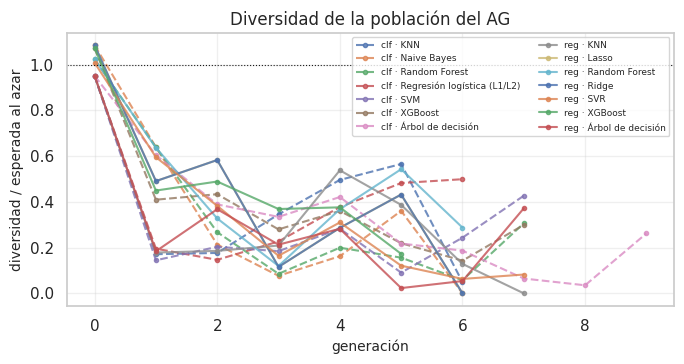

La diversidad está normalizada por la esperada entre puntos al azar en [0,1]^d (√(d/6)). En la generación inicial vale ≈ 1.00 (población aleatoria) y en la última ≈ 0.26: cae a 26 % del valor inicial. Hay convergencia hacia el élite, como se espera con torneo + elitismo y población 4, pero sin colapso total gracias a la mutación y a la reinyección. Con un presupuesto mayor convendría una población más grande para retrasar esta caída.

In [17]:
# Algoritmo genético: diversidad de la población por generación
filas = []
for r in REG + CLF:
    if r["optimizador"] != "Genético (DEAP)":
        continue
    d = len(bm.ESPACIOS[(r["tarea"], r["modelo"])])
    for h in r["historial"] + [r["historial_final"]]:
        for gnr, dv in enumerate(h["diversidad"]):
            filas.append({"tarea": r["tarea"], "modelo": r["modelo"], "generación": gnr, "diversidad_rel": dv / np.sqrt(d / 6)})
D = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(7, 3.8))
for (tarea, mod), g in D.groupby(["tarea", "modelo"]):
    s = g.groupby("generación").diversidad_rel.mean()
    ax.plot(s.index, s.values, marker="o", ms=3, alpha=0.8, ls="-" if tarea == "reg" else "--", label=f"{tarea} · {mod}")
ax.axhline(1, color="k", lw=0.8, ls=":")
ax.set_xlabel("generación"); ax.set_ylabel("diversidad / esperada al azar"); ax.set_title("Diversidad de la población del AG")
ax.legend(fontsize=6.5, ncol=2); ax.grid(alpha=0.3)
plt.tight_layout(); eda.guardar_figura(fig, "e2_diversidad_ag.png"); plt.show()
g0 = D[D.generación == 0].diversidad_rel.mean(); gf = D[D.generación == D.generación.max()].diversidad_rel.mean()
md(f"La diversidad está normalizada por la esperada entre puntos al azar en [0,1]^d (√(d/6)). En la generación inicial vale "
   f"≈ {g0:.2f} (población aleatoria) y en la última ≈ {gf:.2f}: cae a "
   f"{100 * gf / g0:.0f} % del valor inicial. Hay convergencia hacia el élite, como se espera con torneo + elitismo y "
   f"población 4, pero sin colapso total gracias a la mutación y a la reinyección. Con un presupuesto mayor convendría una "
   f"población más grande para retrasar esta caída.")

## 14.6 Estabilidad de cada optimizador ante la semilla

Para separar el efecto del método del efecto del azar, se repitió la búsqueda de XGBoost (regresión) con
**5 semillas** por optimizador sobre todo el entrenamiento (15 evaluaciones, la misma validación interna).
Grid es determinista: sus 5 repeticiones coinciden.

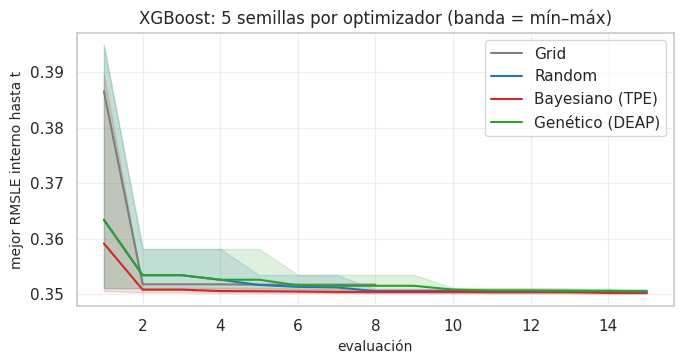

,media,desv,mín,máx,t_por_eval_mediana_s
optimizador,,,,,
Grid,0.35173,0.00000,0.35173,0.35173,0.90535
Random,0.35054,0.00032,0.35022,0.35094,1.23915
Bayesiano (TPE),0.35025,0.00019,0.35008,0.35057,0.95005
Genético (DEAP),0.35049,0.00015,0.35022,0.35058,1.01826


In [18]:
# Estabilidad de cada optimizador ante 5 semillas
S = pd.read_csv(r2.E2 / "semillas_optimizadores.csv")
S["mejor"] = S.groupby(["optimizador", "semilla"]).RMSLE.cummin()
fin = S.groupby(["optimizador", "semilla"]).mejor.last().unstack(0)[OPT]
est = pd.DataFrame({"media": fin.mean(), "desv": fin.std(ddof=1), "mín": fin.min(), "máx": fin.max(),
                    "t_por_eval_mediana_s": S.groupby("optimizador").t_eval_s.median()[OPT]})
eda.guardar_tabla(est.reset_index(), "e2_semillas_optimizadores.csv")
fig, ax = plt.subplots(figsize=(7, 3.8))
for o in OPT:
    g = S[S.optimizador == o].pivot(index="evaluacion", columns="semilla", values="mejor")
    ax.plot(g.index, g.mean(1), color=COL[o], label=o)
    ax.fill_between(g.index, g.min(1), g.max(1), color=COL[o], alpha=0.15)
ax.set_xlabel("evaluación"); ax.set_ylabel("mejor RMSLE interno hasta t"); ax.set_title("XGBoost: 5 semillas por optimizador (banda = mín–máx)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); eda.guardar_figura(fig, "e2_semillas_optimizadores.png"); plt.show()
est.round(5)

In [19]:
# Lectura de la estabilidad ante semillas
o_est = est.drop(index="Grid").desv.idxmin()
md(f"Entre los métodos estocásticos, el más estable ante la semilla es **{o_est}** (desviación {est.loc[o_est, 'desv']:.5f} en el "
   f"RMSLE final). La mejor media la obtiene **{est.media.idxmin()}** ({est.media.min():.4f}). Las diferencias entre semillas "
   f"(≤ {(est['máx'] - est['mín']).max():.4f}) son del mismo orden que las diferencias entre optimizadores, lo que confirma que, "
   f"para este problema, la elección del optimizador influye poco en el resultado final y mucho más en **cuán rápido** se llega "
   f"a él (14.4).")

Entre los métodos estocásticos, el más estable ante la semilla es **Genético (DEAP)** (desviación 0.00015 en el RMSLE final). La mejor media la obtiene **Bayesiano (TPE)** (0.3502). Las diferencias entre semillas (≤ 0.0007) son del mismo orden que las diferencias entre optimizadores, lo que confirma que, para este problema, la elección del optimizador influye poco en el resultado final y mucho más en **cuán rápido** se llega a él (14.4).

## 14.7 Verificación de las reducciones del capítulo 13

El cap. 13 había excluido 28 combinaciones de clasificación **antes** de correrlas: 8 por equivalencia
demostrada (KNN y Naive Bayes con class_weight) y 20 por el tamizaje de baja fidelidad. Para cumplir el
enunciado (140 combinaciones) se ejecutaron todas con el mismo protocolo, lo que permite comprobar si esas
reglas, fijadas sin ver los resultados completos, habrían acertado.

In [20]:
# Equivalencia de class_weight y sin balanceo en KNN y Naive Bayes
Mc = M[(M.tarea == "clf") & (M.estado == "completado")].copy()
eq = []
for mod in ("KNN", "Naive Bayes"):
    for o in OPT:
        a = Mc[(Mc.modelo == mod) & (Mc.balanceo == "class_weight") & (Mc.optimizador == o)]
        b = Mc[(Mc.modelo == mod) & (Mc.balanceo == "sin balanceo") & (Mc.optimizador == o)]
        if len(a) and len(b):
            ra = next(r for r in CLF if r["modelo"] == mod and r["balanceo"] == "class_weight" and r["optimizador"] == o)
            rb = next(r for r in CLF if r["modelo"] == mod and r["balanceo"] == "sin balanceo" and r["optimizador"] == o)
            eq.append({"modelo": mod, "optimizador": o, "AUC externo class_weight": a.externo_media.iloc[0], "AUC externo sin balanceo": b.externo_media.iloc[0],
                       "diferencia": a.externo_media.iloc[0] - b.externo_media.iloc[0],
                       "correlación de rangos (predicciones del bucle externo)": stats.spearmanr(ra["oof_pred"], rb["oof_pred"])[0]})
EQ = pd.DataFrame(eq)
eda.guardar_tabla(EQ, "e2_verificacion_a_priori.csv")
EQ.round(6)

,modelo,optimizador,AUC externo class_weight,AUC externo sin balanceo,diferencia,correlación de rangos (predicciones del bucle externo)
0,KNN,Grid,0.771642,0.771644,-0.000002,0.999608
1,KNN,Random,0.772729,0.772709,0.000020,0.999565
2,KNN,Bayesiano (TPE),0.771622,0.771611,0.000011,0.999574
3,KNN,Genético (DEAP),0.771055,0.771055,0.000000,0.999597
4,Naive Bayes,Grid,0.760466,0.760466,0.000001,0.999948
5,Naive Bayes,Random,0.759682,0.759689,-0.000007,0.999952
6,Naive Bayes,Bayesiano (TPE),0.760395,0.760395,0.000000,0.999949
7,Naive Bayes,Genético (DEAP),0.760148,0.760157,-0.000009,0.999941


In [21]:
md(f"**Equivalencia (KNN y Naive Bayes con class_weight).** La diferencia de AUC externo frente a «sin balanceo» es como máximo "
   f"{EQ.diferencia.abs().max():.2e} y la correlación de rangos de sus predicciones del bucle externo es ≥ "
   f"{EQ['correlación de rangos (predicciones del bucle externo)'].min():.4f}: "
   + ("las dos versiones ordenan las celdas **igual**, como se demostró en el cap. 13.6. Correrlas no aportó información nueva."
      if EQ.diferencia.abs().max() < 1e-3 else "la equivalencia no es exacta en la práctica; ver tabla."))

**Equivalencia (KNN y Naive Bayes con class_weight).** La diferencia de AUC externo frente a «sin balanceo» es como máximo 2.01e-05 y la correlación de rangos de sus predicciones del bucle externo es ≥ 0.9996: las dos versiones ordenan las celdas **igual**, como se demostró en el cap. 13.6. Correrlas no aportó información nueva.

In [22]:
# Validación del tamizaje: posición de los pares descartados
dec = Mc.dropna(subset=["decision_previa"]) if "decision_previa" in Mc else Mc.assign(decision_previa="")
g = dec.groupby(["modelo", "balanceo"]).agg(AUC_externo=("externo_media", "mean"), t_min=("t_total_s", lambda v: v.sum() / 60),
                                          decision=("decision_previa", "first")).reset_index()
g["rango en su modelo"] = g.groupby("modelo").AUC_externo.rank(ascending=False).astype(int)
g["distancia al mejor del modelo"] = g.groupby("modelo").AUC_externo.transform("max") - g.AUC_externo
tam = g[g.decision.str.startswith("descartada en tamizaje")].sort_values(["modelo", "AUC_externo"], ascending=[True, False])
eda.guardar_tabla(g, "e2_verificacion_tamizaje.csv")
tam.round(4)

,modelo,balanceo,AUC_externo,t_min,decision,rango en su modelo,distancia al mejor del modelo
9,Random Forest,SMOTE,0.7712,120.2556,descartada en tamizaje (se ejecutó igual),3,0.0029
8,Random Forest,ADASYN,0.7679,83.3075,descartada en tamizaje (se ejecutó igual),4,0.0063
20,XGBoost,ADASYN,0.7658,14.8477,descartada en tamizaje (se ejecutó igual),4,0.0113
25,Árbol de decisión,SMOTE,0.7378,3.3919,descartada en tamizaje (se ejecutó igual),3,0.0239
24,Árbol de decisión,ADASYN,0.7075,8.1115,descartada en tamizaje (se ejecutó igual),4,0.0542


In [23]:
# Lectura del tamizaje
pasan = g[g.decision == "pasa tamizaje"]
mejor_es_desc = (g.loc[g.groupby("modelo").AUC_externo.idxmax()].decision.str.startswith("descartada en tamizaje")).sum()
md(f"**Tamizaje.** De los {len(tam)} pares descartados por el tamizaje, {int((tam['rango en su modelo'] > 1).sum())} quedaron, con la validación "
   f"anidada completa, por debajo de la mejor técnica de su modelo (distancia media {tam['distancia al mejor del modelo'].mean():.4f} de AUC); "
   f"en {int(mejor_es_desc)} modelo(s) la mejor técnica resultó ser una descartada. El mejor AUC externo global "
   f"({Mc.externo_media.max():.4f}) {'corresponde a un par que pasó el tamizaje' if Mc.sort_values('externo_media').decision_previa.iloc[-1] == 'pasa tamizaje' else 'corresponde a un par descartado'}. "
   f"Correr los descartados costó {tam.t_min.sum():.0f} minutos de cómputo adicional "
   f"({100 * tam.t_min.sum() / g.t_min.sum():.0f} % del total de clasificación). "
   + ("El tamizaje acertó en lo esencial: no habría cambiado ninguna conclusión del proyecto."
      if mejor_es_desc == 0 else "El tamizaje se equivocó en algún caso; las conclusiones usan los 112 resultados completos."))

**Tamizaje.** De los 5 pares descartados por el tamizaje, 5 quedaron, con la validación anidada completa, por debajo de la mejor técnica de su modelo (distancia media 0.0197 de AUC); en 0 modelo(s) la mejor técnica resultó ser una descartada. El mejor AUC externo global (0.7781) corresponde a un par que pasó el tamizaje. Correr los descartados costó 230 minutos de cómputo adicional (20 % del total de clasificación). El tamizaje acertó en lo esencial: no habría cambiado ninguna conclusión del proyecto.

## 14.8 Conclusiones del capítulo

- La validación anidada se ejecutó en las 140 combinaciones del enunciado, con el mismo presupuesto (15
  evaluaciones) y el Pipeline completo dentro de cada pliegue interno.
- **Bayesiano (TPE)** tiene la menor área de regret (la mejor calidad por unidad de presupuesto); la ventaja
  es significativa frente a Grid en regresión y no frente a Random con un presupuesto de solo 15 evaluaciones.
  Con presupuestos mayores la ventaja de un sustituto con Mejora Esperada suele crecer, porque el arranque
  aleatorio pesa menos.
- En la **métrica externa** las diferencias entre optimizadores son pequeñas frente a la variabilidad entre
  años; elegir modelo importa mucho más que elegir optimizador.
- Grid es el peor cuando el espacio tiene más de 2–3 hiperparámetros. El AG converge hacia el élite en pocas
  generaciones por la población pequeña que impone el presupuesto.